# Figuras e tabelas do artigo — *Beyond Logistic Regression*

Notebook único que gera **só** as figuras e tabelas que aparecem no artigo (versão de 18/10/2026), na
ordem do artigo. Saídas em `src/notebooks/figures/artigo/`. Lê `src/results/all/` (rode antes
`concatenate_results.py`), `src/results/forecast_quality/IDADE_BIN/` e, para as Figs. 1–2, os parquets brutos do SRAG
(`RUN_EDA = False` pula essas duas).

| No artigo | Arquivo gerado |
|---|---|
| Fig. 1 | `fig01_cfr_temporal.png` |
| Fig. 2 | `fig02b_age_period_local_scale.png` |
| Fig. 3 | `fig03_vanilla_lr.png` |
| Fig. 4 | `fig04_baselines_lr.png` |
| Fig. 5 | `fig05c_frontier_dp_tpr_fpr_combined.png` |
| Fig. 6 | `fig09b_forecast_vs_real_combined.png` |
| Tab. 3 | `tab03b_absolute_rates_lr_combined.tex` |
| Tab. 4 | `tab04_alpha_lr.tex` |
| Tab. 5 | `tab05b_temporal_lr_combined.tex` |
| Tab. 6 | `tab06c_baselines_models.tex` |
| Tab. 7 | `tab05c_temporal_baselines_models.tex` |
| Tab. 8 | `tab08b_mae_by_period.tex` |
| Tab. 9 | `tab10f_forecast_error_vs_fairness.tex` |

As Tabs. 1 e 2 do artigo são escritas à mão.

Seção 5 do notebook (*Dataset analytics*, para o Dataset Review; ainda sem número no artigo): `tabds01_dataset_overview.tex`,
`tabds02_preprocessing_funnel.tex`, `tabds03_period_profile.tex`, `tabds04_missing_raw.tex`, `tabds05_feature_shift.tex`,
`tabds06_selection_by_year.tex`, `tabds07_proxy_correlations.tex` e `figds01_records_per_batch.png`.

## 0. Setup

In [ ]:
import re
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.textpath import TextPath
from matplotlib.ticker import FuncFormatter

# O notebook vive em src/notebooks/ -> raiz do repo dois níveis acima
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))
sys.path.append(str(ROOT / 'src' / 'tools'))

from metrics_utils import (  # noqa: E402
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)
from vanilla_shift_chart import build_chart  # noqa: E402

# Gera as Figs. 1–2 a partir dos parquets brutos do SRAG (pesado). False pula só essas duas.
RUN_EDA = True

# Métricas snapshot do artigo (metrics_utils._SNAPSHOT_METRICS também inclui eq_odds_diff, fora do artigo)
ARTICLE_METRICS = [
    ('acc', 'Accuracy'),
    ('auc', 'AUC-ROC'),
    ('dp', 'Statistical Parity\nDifference (ΔSP)'),
    ('tpr_diff', 'True Positive Rate\nDifference (ΔTPR)'),
    ('fpr_diff', 'False Positive Rate\nDifference (ΔFPR)'),
]
# Rótulos curtos (eixos y): siglas definidas no artigo
AXIS_LABELS = {'acc': 'Accuracy', 'auc': 'AUC-ROC', 'dp': 'ΔSP', 'tpr_diff': 'ΔTPR', 'fpr_diff': 'ΔFPR'}
metric_cols = [col for col, _ in ARTICLE_METRICS]
rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']

MODEL_ABBR = {'logistic_regression': 'lr', 'xgboost': 'xgboost', 'random_forest': 'rf'}
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'xgboost': 'XGBoost', 'random_forest': 'Random Forest'}

PERIOD_LABELS_EN = {
    'pré-pandemia': 'pre-pandemic',
    'pandemia aguda 1': 'acute pandemic 1',
    'pandemia aguda 2': 'acute pandemic 2',
    'transição': 'transition',
    'endêmico': 'endemic',
}
PERIOD_ORDER_EN = list(PERIOD_LABELS_EN.values())

ART_DIR = ROOT / 'src' / 'notebooks' / 'figures' / 'artigo'
ART_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name, dpi=120):
    out_path = ART_DIR / name
    fig.savefig(out_path, dpi=dpi, bbox_inches='tight')
    print(f'Figura salva em {out_path}')
    plt.show()


def save_tex(lines, name):
    out_path = ART_DIR / name
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    print(f'Tabela salva em {out_path}')
    return '\n'.join(lines)

In [2]:
def load_filtered(csv_name, models, technique='sma'):
    """Filtro canônico de todo o artigo: kamiran_rw, train_window none e a técnica de forecasting."""
    df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / csv_name, low_memory=False)
    techniques = [technique] if isinstance(technique, str) else technique
    return df[
        (df['fairness_correction'] == 'kamiran_rw')
        & (df['train_window'].astype(str) == 'none')
        & (df['forecasting_technique'].isin(techniques))
        & (df['model_name'].isin(models))
    ].copy()


ALL_MODELS = list(MODEL_LABELS)
# Um único forecast window em todo o artigo: vanilla/static são treinados uma vez, no primeiro batch
# após o warm-up, que depende do fw (docs/fig4_modelos_plan.md, seção 3). Misturar fws mistura modelos de referência.
FORECAST_WINDOW = 5
assessment_df = load_filtered('assessment_all_baselines.csv', ALL_MODELS).query('forecast_window == @FORECAST_WINDOW')
absolute_df = load_filtered('absolute_results_df.csv', ALL_MODELS).query('forecast_window == @FORECAST_WINDOW')
temporal_df = load_filtered('temporal_results_df.csv', ALL_MODELS).query('forecast_window == @FORECAST_WINDOW')

assessment_df.groupby(['model_name', 'batch_type', 'baseline']).size().unstack('baseline')

baseline                        abcinml  dynamic  static  vanilla
model_name          batch_type                                   
logistic_regression monthly        2640      240     240      240
                    weekly        11649     1059    1059     1059
random_forest       monthly        2640      240     240      240
                    weekly        11649     1059    1059     1059
xgboost             monthly        2640      240     240      240
                    weekly        11649     1059    1059     1059

In [3]:
# ── Versões combinadas (monthly + weekly no mesmo eixo) ─────────────────────
# Os gráficos originais usam a posição do batch no eixo x; para sobrepor monthly (~83 batches)
# e weekly (~360) é preciso um eixo de datas reais.
from metrics_utils import _PERIOD_SPANS, _VLINES  # noqa: E402

BT_ORDER = ['monthly', 'weekly']
MA_WINDOW_COMBINED = {'monthly': 5, 'weekly': 20}  # 5 meses ≈ 20 semanas


def batch_dates(batches, batch_type):
    """Datas reais dos batches; monthly vai para o meio do mês, alinhado ao weekly."""
    dts = _batch_to_datetime([str(b) for b in batches], batch_type)
    return dts + pd.Timedelta(days=14) if batch_type == 'monthly' else dts


def add_period_spans_dt(ax):
    """Faixas de período e vlines em datas (mesmas cores de metrics_utils, rótulos em inglês)."""
    handles = []
    for start, end, name, color in _PERIOD_SPANS:
        handles.append(ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.20, color=color,
                                  zorder=0, label=PERIOD_LABELS_EN[name]))
    for ts, _ in _VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=0.8, alpha=0.6, zorder=1)
    return handles


def fmt_date_axis(ax, dates):
    """Eixo x de datas recortado ao intervalo dos dados, com um tick por ano."""
    ax.set_xlim(min(dates) - pd.Timedelta(days=15), max(dates) + pd.Timedelta(days=15))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def temporal_side_by_side_latex(tables, first_col, caption, label, filename):
    """Métricas temporais com monthly e weekly em colunas lado a lado (M / W) por métrica.

    TS e MBD medem variação entre batches consecutivos (passo de um mês vs. de uma semana),
    então não são combinadas — só postas lado a lado. Negrito = menor valor de cada coluna.
    """
    wide = pd.concat({bt: tables[bt] for bt in BT_ORDER}, axis=1).swaplevel(axis=1)
    wide = wide[[(m, bt) for m in TEMPORAL_METRICS for bt in BT_ORDER]]
    groups = ' & '.join(rf'\multicolumn{{2}}{{c}}{{{h}}}' for h in TEMPORAL_HEADERS)
    rules = ' '.join(rf'\cmidrule(lr){{{2 + 2 * i}-{3 + 2 * i}}}' for i in range(len(TEMPORAL_METRICS)))
    lines = [
        r'\begin{table}',
        r'  \small',
        rf'  \caption{{{caption} M = monthly (forecast window = {TABLE_WINDOW["monthly"]}), '
        rf'W = weekly (forecast window = {TABLE_WINDOW["weekly"]}).}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{l' + 'r' * wide.shape[1] + '}',
        r'    \toprule',
        rf'     & {groups} \\',
        rf'    {rules}',
        f'    {first_col} & ' + ' & '.join('M' if bt == 'monthly' else 'W' for _, bt in wide.columns) + r' \\',
        r'    \midrule',
    ]
    for name, row in wide.iterrows():
        cells = [
            rf'\textbf{{{v:.2f}\%}}' if v == wide[col].min() else rf'{v:.2f}\%'
            for col, v in row.items()
        ]
        lines.append(f'    {name} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, filename)


HIGHER_IS_BETTER = {'acc', 'auc'}  # demais métricas: diferenças entre grupos, melhor perto de 0


def _optimum_arrow(ax, positive, axis='y', scale=1.0):  # scale < 1 em figuras pequenas
    """Seta sem texto junto ao nome do eixo, apontando para o valor ótimo.

    axis='y': à esquerda do eixo y (números + nome); axis='x': abaixo do eixo x (números + nome).
    A posição ao longo do eixo é em frações do painel (igual em todos os painéis); a distância até
    o eixo é em frações da caixa do eixo, então a seta não sobrepõe os números nem o nome.
    """
    lo, hi = (0.3, 0.7) if positive else (0.7, 0.3)
    if axis == 'y':
        coords = (lambda renderer: ax.yaxis.get_tightbbox(renderer), 'axes fraction')
        tail, head = (-0.30, lo), (-0.30, hi)
    else:
        coords = ('axes fraction', lambda renderer: ax.xaxis.get_tightbbox(renderer))
        tail, head = (lo, -0.15), (hi, -0.15)
    ax.annotate('', xy=head, xytext=tail, xycoords=coords, textcoords=coords, annotation_clip=False,
                arrowprops=dict(arrowstyle='-|>', color='#666666', lw=2.6 * scale, mutation_scale=24 * scale))


## 1. Dataset Review (seção 4.1)

### Figs. 1–2 — SRAG bruto (controladas por `RUN_EDA`)

In [4]:
# Estilo próprio do EDA, aplicado só dentro das Figs. 1–2 (não vaza para as demais)
EDA_STYLE = 'seaborn-v0_8-whitegrid'
EDA_RC = {
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
}

# ── Paleta de períodos (seaborn 'deep', 5 cores) ─────────────────────────────
PERIOD_ORDER = ['pre-pandemic', 'acute pandemic 1', 'acute pandemic 2', 'transition', 'endemic']
PERIOD_COLORS = dict(zip(PERIOD_ORDER, sns.color_palette('deep', 5)))

PERIOD_SPANS = [
    ('2019-07-01', '2020-03-01', 'pre-pandemic'),
    ('2020-03-01', '2022-01-01', 'acute pandemic 1'),
    ('2022-01-01', '2023-01-01', 'acute pandemic 2'),
    ('2023-01-01', '2024-01-01', 'transition'),
    ('2024-01-01', '2026-03-01', 'endemic'),
]
VLINES = [
    (pd.Timestamp('2020-03-01'), 'Mar/2020'),
    (pd.Timestamp('2022-01-01'), 'Jan/2022'),
    (pd.Timestamp('2023-01-01'), 'Jan/2023'),
    (pd.Timestamp('2024-01-01'), 'Jan/2024'),
]

MONTH_EN = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
            7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}


def fmt_date(x, pos):
    try:
        dt = mdates.num2date(x)
        return f'{MONTH_EN[dt.month]}/{dt.year}'
    except Exception:
        return ''


def add_period_spans(ax):
    for start, end, nome in PERIOD_SPANS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   alpha=0.20, color=PERIOD_COLORS[nome])


def add_vlines(ax):
    for ts, label in VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=1.2, alpha=0.8)
        ax.text(ts, 0.97, label, rotation=90, va='top', ha='right', fontsize=9,
                color='#555555', transform=ax.get_xaxis_transform())


def fmt_xaxis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_date))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')


def load_srag():
    """Lê os parquets brutos e prepara obito/periodo/idade (como no 01_eda)."""
    raw_dir = ROOT / 'src' / 'data' / 'SRAG' / 'raw'
    cols = ['DT_NOTIFIC', 'EVOLUCAO', 'NU_IDADE_N']
    srag = pd.concat(
        (pd.read_parquet(f, columns=cols) for f in sorted(raw_dir.glob('*.parquet'))),
        ignore_index=True,
    )
    srag['EVOLUCAO'] = pd.to_numeric(srag['EVOLUCAO'], errors='coerce').astype('Int64')
    srag['DT_NOTIFIC'] = pd.to_datetime(srag['DT_NOTIFIC'], errors='coerce')

    # Período de análise (jul/2019 – fev/2026)
    srag = srag[
        (srag['DT_NOTIFIC'] >= pd.Timestamp('2019-07-01'))
        & (srag['DT_NOTIFIC'] <= pd.Timestamp('2026-02-28'))
    ].copy()

    # obito: True=EVOLUCAO 2, False=EVOLUCAO 1, NaN para 3 e 9
    srag['obito'] = srag['EVOLUCAO'].map({1: False, 2: True})
    period_bins = [pd.Timestamp(start) for start, _, _ in PERIOD_SPANS] + [pd.Timestamp('2026-03-01')]
    srag['periodo'] = pd.cut(srag['DT_NOTIFIC'], bins=period_bins, labels=PERIOD_ORDER,
                             right=False, ordered=True)

    # NU_IDADE_N é armazenado como Decimal → converter via string
    srag['idade'] = pd.to_numeric(srag['NU_IDADE_N'].astype(str), errors='coerce')
    srag.loc[(srag['idade'] < 0) | (srag['idade'] > 110), 'idade'] = np.nan
    print(f'Registros no período jul/2019–fev/2026: {len(srag):,}')
    return srag

In [ ]:
def plot_fig01(srag):
    """Fig. 1 — série temporal semanal da taxa de letalidade."""
    # count() ignora NaN → conta só desfechos definidos (EVOLUCAO 1 ou 2)
    weekly = (
        srag.groupby(srag['DT_NOTIFIC'].dt.to_period('W'))['obito']
        .agg(casos='count', obitos='sum')
        .reset_index()
    )
    weekly['letalidade'] = weekly['obitos'] / weekly['casos']
    weekly['dt'] = weekly['DT_NOTIFIC'].dt.start_time

    with plt.style.context(EDA_STYLE), plt.rc_context(EDA_RC):
        fig, ax = plt.subplots(figsize=(14, 5))
        add_period_spans(ax)
        ax.plot(weekly['dt'], weekly['letalidade'] * 100, color='#333333', linewidth=1.2, zorder=3)
        add_vlines(ax)
        fmt_xaxis(ax)
        ax.set_ylabel('Case Fatality Rate (%)')
        ax.set_xlabel('Notification Week')

        handles = [plt.Rectangle((0, 0), 1, 1, color=PERIOD_COLORS[p], alpha=0.4) for p in PERIOD_ORDER]
        ax.legend(handles, PERIOD_ORDER, loc='upper right', title='Period', framealpha=0.9)
        plt.tight_layout()
        save_fig(fig, 'fig01_cfr_temporal.png')


def plot_fig02b(srag):
    """Fig. 2b — mesma grade da Fig. 2, com cada painel dividido em duas partes verticais (3:1).

    Parte superior: eixo y compartilhado por linha (sharey='row'), para comparar os períodos.
    Parte inferior: mini painel cinza com os mesmos dados e eixo y livre (escala local).
    O eixo x é compartilhado por todos os painéis, então fica perfeitamente alinhado.
    """
    age_bins = np.arange(0, 113, 5)
    age_mids = age_bins[:-1] + 2.5
    bar_width = 3.8
    srag_ob = srag[srag['obito'] == True]  # noqa: E712 — coluna object com NaN

    data = {}
    for periodo in PERIOD_ORDER:
        sub_c = srag[srag['periodo'] == periodo]['idade'].dropna()
        sub_o = srag_ob[srag_ob['periodo'] == periodo]['idade'].dropna()
        counts_c, _ = np.histogram(sub_c.values, bins=age_bins)
        counts_o, _ = np.histogram(sub_o.values, bins=age_bins)
        with np.errstate(invalid='ignore', divide='ignore'):
            pct = np.where(counts_c > 0, counts_o / counts_c * 100, np.nan)
        data[periodo] = dict(cases=counts_c, deaths=counts_o, pct=pct, n_c=len(sub_c), n_o=len(sub_o))

    count_fmt = plt.FuncFormatter(lambda x, _: f'{int(x):,}')
    count_fmt_low = plt.FuncFormatter(lambda x, _: f'{x / 1000:g}k' if x >= 1000 else f'{int(x)}')  # compacto no mini painel
    pct_fmt = plt.FuncFormatter(lambda x, _: f'{x:.0f}%')
    rows = [('Cases', 'cases', count_fmt, count_fmt_low), ('Deaths', 'deaths', count_fmt, count_fmt_low),
            ('Fatality Rate (%)', 'pct', pct_fmt, pct_fmt)]
    n_cols = len(PERIOD_ORDER)

    with plt.style.context(EDA_STYLE), plt.rc_context(EDA_RC):
        fig = plt.figure(figsize=(22, 15))
        outer = fig.add_gridspec(len(rows), n_cols, hspace=0.24, wspace=0.40,
                                 left=0.08, right=0.99, top=0.92, bottom=0.06)
        ref = None          # primeiro painel: referência do eixo x compartilhado
        first_top = {}      # primeiro painel superior de cada linha: referência do sharey='row'
        for r, (label, key, fmt, fmt_low) in enumerate(rows):
            for c, periodo in enumerate(PERIOD_ORDER):
                color = PERIOD_COLORS[periodo]
                bar_kw = dict(width=bar_width, color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
                inner = outer[r, c].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.10)
                ax_top = fig.add_subplot(inner[0], sharex=ref, sharey=first_top.get(r))
                ax_low = fig.add_subplot(inner[1], sharex=ref or ax_top, facecolor='#eeeeee')
                ref = ref or ax_top
                first_top.setdefault(r, ax_top)

                y = data[periodo][key]
                ax_top.bar(age_mids, y, **bar_kw)
                ax_low.bar(age_mids, y, **bar_kw)

                ax_top.yaxis.set_major_formatter(fmt)
                ax_low.yaxis.set_major_formatter(fmt_low)
                ax_top.tick_params(axis='y', labelsize=20)
                ax_low.tick_params(axis='y', labelsize=17)
                ax_top.tick_params(axis='x', labelbottom=False)
                ax_low.tick_params(axis='x', labelsize=20, labelbottom=(r == len(rows) - 1))
                ax_low.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=3))
                ax_low.set_ylim(bottom=0)  # eixo y livre: só o topo se ajusta aos dados do painel
                ax_low.grid(axis='x', visible=False)
                for spine in ax_low.spines.values():
                    spine.set_color('#bbbbbb')

                if r == 0:
                    ax_top.set_title(f"{periodo}\n(n={data[periodo]['n_c']:,})", fontsize=24, fontweight='bold')
                if r == 1:
                    ax_top.text(0.03, 0.97, f"n={data[periodo]['n_o']:,}", transform=ax_top.transAxes,
                                ha='left', va='top', fontsize=20, color='#333333')
                if r == len(rows) - 1:
                    ax_low.set_xlabel('Age (years)', fontsize=23)
                if c == 0:
                    ax_top.set_ylabel(label, fontsize=26)
                if key == 'pct':
                    ax_top.set_ylim(0, 60)

        save_fig(fig, 'fig02b_age_period_local_scale.png')


if RUN_EDA:
    srag = load_srag()
    plot_fig01(srag)
    plot_fig02b(srag)
    del srag
else:
    print('RUN_EDA = False — Figs. 1–2 puladas')

### Fig. 3 — Vanilla LR sob distribution shift

In [ ]:
# Mesma função usada pela CLI src/tools/vanilla_shift_chart.py (lê a pasta fw_5).
# Os rótulos das métricas vêm de ARTICLE_METRICS: a ferramenta lê o _FAIRNESS_METRICS do módulo em tempo de chamada.
import vanilla_shift_chart  # noqa: E402

vanilla_shift_chart._FAIRNESS_METRICS = [m for m in ARTICLE_METRICS if m[0] in ('dp', 'tpr_diff', 'fpr_diff')]
fig = build_chart('IDADE_BIN', 'logistic_regression', forecast_window=5)
# a ferramenta usa o mesmo texto no título e no eixo y; no eixo y fica só a sigla
_col_by_title = {label: col for col, label in ARTICLE_METRICS}
for ax in fig.axes:
    if ax.get_title() in _col_by_title:
        ax.set_ylabel(AXIS_LABELS[_col_by_title[ax.get_title()]], fontsize=20)
save_fig(fig, 'fig03_vanilla_lr.png')

## 2. Logistic Regression baseline (seção 4.2)

### Fig. 4 — Comparação dos 4 baselines (LR)

In [ ]:
def plot_baselines_row(axes, df_row, batch_type, moving_avg_window):
    """Replica a lógica de _generate_comparative_chart em uma fileira de eixos."""
    df = df_row.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in ARTICLE_METRICS:
        values = df_row[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(ARTICLE_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(x_pos, ma.values, color=_BASELINE_COLORS.get(bt, None),
                            linewidth=2.5, label=bt, zorder=3)
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(AXIS_LABELS[col], fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        # um tick no primeiro batch de cada ano, rotulado só com o ano
        year_starts = [i for i, b in enumerate(all_batch_labels) if i == 0 or b[:4] != all_batch_labels[i - 1][:4]]
        ax.set_xticks(year_starts)
        ax.set_xticklabels([all_batch_labels[i][:4] for i in year_starts], rotation=45)
        # direção do valor ótimo: accuracy/AUC para cima; diferenças entre grupos para baixo (zero)
        _optimum_arrow(ax, positive=col in HIGHER_IS_BETTER)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


def plot_baselines_comparison(model_name):
    model_df = assessment_df[assessment_df['model_name'] == model_name]
    fig = plt.figure(figsize=(28, 13), layout='constrained')
    subfigs = fig.subfigures(2, 1)

    rows = [
        ('monthly', model_df[model_df['batch_type'] == 'monthly'], 5),
        ('weekly', model_df[model_df['batch_type'] == 'weekly'], 20),
    ]

    baseline_handles, period_handles = [], []
    for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
        axes = subfig.subplots(1, len(ARTICLE_METRICS))
        subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
        bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
        if not baseline_handles:
            baseline_handles, period_handles = bh, ph

    # Ajustes pós-plot: alpha das faixas (mesmo da Fig. 1) e fonte dos rótulos das vlines
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_fontsize(13)

    all_handles = baseline_handles + period_handles
    legend_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in all_handles]
    # faixa reservada no rodapé: a legenda fica abaixo dos anos do eixo x, com folga
    fig.get_layout_engine().set(rect=(0, 0.07, 1, 0.93))
    leg = fig.legend(all_handles, legend_labels, loc='lower center', bbox_to_anchor=(0.5, 0),
                     ncol=len(all_handles), fontsize=20, framealpha=0.9)
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)
    return fig


save_fig(plot_baselines_comparison('logistic_regression'), 'fig04_baselines_lr.png')

### Tabela 3 — TPR/FPR absolutos por baseline e grupo (LR)

In [ ]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: linhas = baseline, colunas = (TPR/FPR) × (S0/S1), média sobre os batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # média por (baseline, batch) e depois média sobre os batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


#### Tabela 3 — versão do artigo (média de monthly e weekly)

In [10]:
def absolute_rates_pooled(model_name):
    """Média, célula a célula, das pivots monthly e weekly (pesos iguais por batch type)."""
    return ((absolute_rates_pivot(model_name, 'monthly') + absolute_rates_pivot(model_name, 'weekly')) / 2).round(2)


def pooled_pivot_latex(model_name, model_label, label):
    lines = [
        r'\begin{table}',
        rf'  \caption{{Mean TPR and FPR by Baseline and Group, averaged over monthly and weekly batches - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrrr}',
        r'    \toprule',
        r'     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\',
        r'    \cmidrule(lr){2-3} \cmidrule(lr){4-5}',
        r'    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\',
        r'    \midrule',
    ]
    piv = absolute_rates_pooled(model_name)
    for baseline, row in zip(piv.index, piv.values):
        lines.append(f'    {baseline} & ' + ' & '.join(rf'{v:.2f}\%' for v in row) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab03b_absolute_rates_{MODEL_ABBR[model_name]}_combined.tex')


print(pooled_pivot_latex('logistic_regression', 'Logistic Regression', 'tab:absolute-rates-lr-combined'))
absolute_rates_pooled('logistic_regression')

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab03b_absolute_rates_lr_combined.tex
\begin{table}
  \caption{Mean TPR and FPR by Baseline and Group, averaged over monthly and weekly batches - Logistic Regression.}
  \label{tab:absolute-rates-lr-combined}
  \begin{tabular}{lrrrr}
    \toprule
     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5}
    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\
    \midrule
    vanilla & 20.26\% & 43.72\% & 2.19\% & 16.20\% \\
    static & 28.25\% & 21.14\% & 3.56\% & 5.35\% \\
    dynamic & 37.52\% & 27.26\% & 3.73\% & 4.28\% \\
    abcinml & 39.14\% & 25.95\% & 3.94\% & 4.03\% \\
    \bottomrule
  \end{tabular}
\end{table}


Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            20.26          43.72            2.19          16.20
static             28.25          21.14            3.56           5.35
dynamic            37.52          27.26            3.73           4.28
abcinml            39.14          25.95            3.94           4.03

### Tabela 4 — Variação de α no ABCInML (LR, monthly)

In [11]:
ALPHA_HEADERS = {
    'acc': r'Accuracy $\uparrow$',
    'auc': r'AUC-ROC $\uparrow$',
    'dp': r'DP Diff. $\downarrow$',
    'tpr_diff': r'TPR Diff. $\downarrow$',
    'fpr_diff': r'FPR Diff. $\downarrow$',
}
PERF_METRICS = {'acc', 'auc'}  # maior é melhor; as de fairness, menor é melhor


def alpha_table(model_name, batch_type='monthly', as_percent=True):
    """Linhas = alpha, colunas = métricas snapshot; média sobre os batches do abcinml."""
    abc = assessment_df[
        (assessment_df['model_name'] == model_name)
        & (assessment_df['batch_type'] == batch_type)
        & (assessment_df['baseline'] == 'abcinml')
    ]
    tbl = abc.groupby('alpha')[metric_cols].mean().sort_index()
    return (tbl * 100 if as_percent else tbl).round(2)


def alpha_table_latex(model_name, model_label, label, batch_type='monthly'):
    """Tabela no estilo da Tabela 4 do artigo: bandas Performance/Fairness, melhor valor em negrito."""
    tbl = alpha_table(model_name, batch_type)
    n_perf = sum(c in PERF_METRICS for c in metric_cols)
    n_fair = len(metric_cols) - n_perf
    header = ' & '.join([r'$\alpha$'] + [ALPHA_HEADERS[c] for c in metric_cols])
    lines = [
        r'\begin{table}',
        rf'  \caption{{ABCInML alpha parameter variation - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{l' + 'r' * len(metric_cols) + '}',
        r'    \toprule',
        rf'     & \multicolumn{{{n_perf}}}{{c}}{{Performance}} & \multicolumn{{{n_fair}}}{{c}}{{Fairness}} \\',
        rf'    \cmidrule(lr){{2-{1 + n_perf}}} \cmidrule(lr){{{2 + n_perf}-{1 + len(metric_cols)}}}',
        rf'    {header} \\',
        r'    \midrule',
    ]
    best = {c: (tbl[c].max() if c in PERF_METRICS else tbl[c].min()) for c in metric_cols}
    for alpha, row in tbl.iterrows():
        cells = [
            rf'\textbf{{{v:.2f}\%}}' if v == best[col] else rf'{v:.2f}\%'
            for col, v in row.items()
        ]
        lines.append(f'    {alpha:.1f} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab04_alpha_{MODEL_ABBR[model_name]}.tex')


print(alpha_table_latex('logistic_regression', 'Logistic Regression', 'tab:alpha-lr'))
alpha_table('logistic_regression')

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab04_alpha_lr.tex
\begin{table}
  \caption{ABCInML alpha parameter variation - Logistic Regression.}
  \label{tab:alpha-lr}
  \begin{tabular}{lrrrrr}
    \toprule
     & \multicolumn{2}{c}{Performance} & \multicolumn{3}{c}{Fairness} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-6}
    $\alpha$ & Accuracy $\uparrow$ & AUC-ROC $\uparrow$ & DP Diff. $\downarrow$ & TPR Diff. $\downarrow$ & FPR Diff. $\downarrow$ \\
    \midrule
    0.0 & 86.49\% & 77.80\% & \textbf{3.22\%} & 16.39\% & 0.88\% \\
    0.1 & 86.51\% & 78.10\% & 3.35\% & 15.72\% & 0.80\% \\
    0.2 & 86.54\% & 78.38\% & 3.50\% & 15.07\% & 0.71\% \\
    0.3 & 86.56\% & 78.65\% & 3.65\% & 14.50\% & 0.66\% \\
    0.4 & 86.59\% & 78.91\% & 3.81\% & 13.86\% & 0.62\% \\
    0.5 & 86.61\% & 79.16\% & 3.97\% & 13.25\% & \textbf{0.60\%} \\
    0.6 & 86.64\% & 79.40\% & 4.13\% & 12.67\% & 0.61\% \\
    0.7 & 86.66\% & 79.63\% & 4.29\% & 12.04\% & 0.64

,acc,auc,dp,tpr_diff,fpr_diff
alpha,,,,,
0.0,86.49,77.80,3.22,16.39,0.88
0.1,86.51,78.10,3.35,15.72,0.80
0.2,86.54,78.38,3.50,15.07,0.71
0.3,86.56,78.65,3.65,14.50,0.66
0.4,86.59,78.91,3.81,13.86,0.62
0.5,86.61,79.16,3.97,13.25,0.60
0.6,86.64,79.40,4.13,12.67,0.61
0.7,86.66,79.63,4.29,12.04,0.64
0.8,86.68,79.85,4.45,11.41,0.70


### Tabela 5 — Métricas temporais por baseline (LR)

In [ ]:
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']
# Cabeçalhos do LaTeX: ↓ = menor é melhor (as três temporais são ↓)
TEMPORAL_HEADERS = [r'Max. Bias $\downarrow$', r'Temporal Stability $\downarrow$', r'Max. Bias Diff. $\downarrow$']
TABLE_WINDOW = {'monthly': FORECAST_WINDOW, 'weekly': FORECAST_WINDOW}  # mesma janela nos dois batch types


def temporal_metrics_table(model_name, batch_type, as_percent=True):
    """Linhas = baseline, colunas = métricas temporais; abcinml = média sobre os alphas."""
    fw = TABLE_WINDOW[batch_type]
    sub = temporal_df[
        (temporal_df['model_name'] == model_name)
        & (temporal_df['batch_type'] == batch_type)
        & (temporal_df['forecast_window'] == fw)
    ]
    missing = [b for b in _BASELINE_ORDER if b not in sub['baseline'].unique()]
    assert not missing, f'{model_name} {batch_type} fw={fw}: faltam {missing}'
    tbl = sub.groupby('baseline')[TEMPORAL_METRICS].mean().reindex(_BASELINE_ORDER)
    tbl.index.name = 'Baseline'
    return (tbl * 100 if as_percent else tbl).round(2)


#### Tabela 5b — versão combinada (monthly e weekly lado a lado)

In [13]:
print(temporal_side_by_side_latex(
    {bt: temporal_metrics_table('logistic_regression', bt) for bt in BT_ORDER},
    'Baseline', 'Temporal Fairness Metrics by Baseline - Logistic Regression.',
    'tab:temporal-lr-combined', 'tab05b_temporal_lr_combined.tex',
))

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab05b_temporal_lr_combined.tex


\begin{table}
  \small
  \caption{Temporal Fairness Metrics by Baseline - Logistic Regression. M = monthly (forecast window = 3), W = weekly (forecast window = 5).}
  \label{tab:temporal-lr-combined}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{Max. Bias $\downarrow$} & \multicolumn{2}{c}{Temporal Stability $\downarrow$} & \multicolumn{2}{c}{Max. Bias Diff. $\downarrow$} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Baseline & M & W & M & W & M & W \\
    \midrule
    vanilla & 33.73\% & 36.42\% & 1.29\% & 1.95\% & 7.66\% & 24.94\% \\
    static & 10.10\% & 18.12\% & 1.14\% & 1.55\% & 6.19\% & 10.99\% \\
    dynamic & \textbf{8.25\%} & 10.97\% & \textbf{0.99\%} & 1.13\% & \textbf{4.78\%} & \textbf{8.14\%} \\
    abcinml & 9.13\% & \textbf{9.95\%} & 1.17\% & \textbf{1.12\%} & 5.00\% & 8.65\% \\
    \bottomrule
  \end{tabular}
\end{table}


## 3. Expansion to Non Linear Models (seção 4.3)

### Fig. 5 — Accuracy × DP / TPR / FPR variando α (LR × XGBoost × RF)

In [ ]:
FRONTIER_MODELS = ['logistic_regression', 'xgboost', 'random_forest']
MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728', 'random_forest': '#2ca02c'}
MODEL_MARKERS = {'logistic_regression': 'o', 'xgboost': 's', 'random_forest': '^'}
LABEL_LANES = {'logistic_regression': (-9, 'right'), 'random_forest': (9, 'left'), 'xgboost': (62, 'left')}
METRIC_LABELS = dict(ARTICLE_METRICS)


def frontier_points(model_name, batch_type, metric):
    """Média de accuracy e da métrica (em %) por alpha, só abcinml."""
    abc = assessment_df[
        (assessment_df['model_name'] == model_name)
        & (assessment_df['batch_type'] == batch_type)
        & (assessment_df['baseline'] == 'abcinml')
    ]
    return abc.groupby('alpha')[['acc', metric]].mean().sort_index() * 100


def _underline(ax, xy, dx, dy, ha, text, color, fontsize=12):
    """Sublinha, na cor do modelo, um rótulo posicionado a (dx, dy) pontos do ponto xy (em dados)."""
    width = TextPath((0, 0), text, size=fontsize).get_extents().width  # em pontos
    x0, x1 = (dx - width, dx) if ha == 'right' else (dx, dx + width)
    # Coordenadas em pontos relativas ao ponto de dados: acompanha o layout final do savefig
    trans = (
        mtransforms.Affine2D().scale(1 / 72) + ax.figure.dpi_scale_trans
        + mtransforms.ScaledTranslation(*xy, ax.transData)
    )
    ax.add_artist(Line2D([x0, x1], [dy - 8, dy - 8], transform=trans, color=color, linewidth=2.2))


def _draw_frontier(ax, batch_type, metric, points_fn=frontier_points, fs=12):
    """fs = fonte base (rótulos α e setas); eixos, ticks e legenda escalam a partir dela."""
    y_values = []
    for model in FRONTIER_MODELS:
        pts = points_fn(model, batch_type, metric)
        y_values.extend(pts[metric])
        ax.scatter(
            pts['acc'], pts[metric],
            color=MODEL_COLORS[model], marker=MODEL_MARKERS[model], s=60,
            edgecolor='white', linewidth=1.0, zorder=3, label=MODEL_LABELS[model],
        )
        # Rótulos só nas pontas (sentido de alpha); uma faixa de rótulos por modelo
        dx, ha = LABEL_LANES[model]
        a0, a1 = pts.index.min(), pts.index.max()
        # Afasta verticalmente os dois rótulos do mesmo modelo (evita encostarem quando próximos)
        away = 6 if pts.loc[a0, metric] >= pts.loc[a1, metric] else -6
        for alpha, dy in ((a0, away), (a1, -away)):
            text = f'α = {alpha:g}'
            xy = (pts.loc[alpha, 'acc'], pts.loc[alpha, metric])
            ax.annotate(text, xy, xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
                        fontsize=fs, color='#333333')
            _underline(ax, xy, dx, dy, ha, text, MODEL_COLORS[model], fontsize=fs)

    ax.margins(y=0.08)  # espaço para os rótulos das pontas
    ax.set_xlim(80, 90)  # escala fixa de accuracy, comum a todas as fronteiras
    ax.set_xlabel('Accuracy (%)', fontsize=fs + 3)
    ax.set_ylabel(f'{AXIS_LABELS.get(metric, metric)} (%)', fontsize=fs + 3)
    ax.set_title(f'{batch_type} batches', fontsize=fs + 3, fontweight='bold')
    ax.tick_params(axis='both', labelsize=fs + 1)
    ax.grid(color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=fs + 1, framealpha=0.9, loc='best')

    _optimum_arrow(ax, positive=True, axis='x')
    # Diferenças entre grupos melhoram em direção a zero: o sentido depende do sinal dos valores
    y_positive = metric in HIGHER_IS_BETTER or pd.Series(y_values).median() < 0
    _optimum_arrow(ax, positive=y_positive)


In [ ]:
def frontier_points_pooled(model_name, batch_type, metric):
    """Média, por alpha, dos pontos monthly e weekly (pesos iguais; batch_type é ignorado)."""
    return (frontier_points(model_name, 'monthly', metric) + frontier_points(model_name, 'weekly', metric)) / 2


#### Fig. 5 — 1×3, painéis quadrados (monthly e weekly agregados por α)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig05c_frontier_dp_tpr_fpr_combined.png


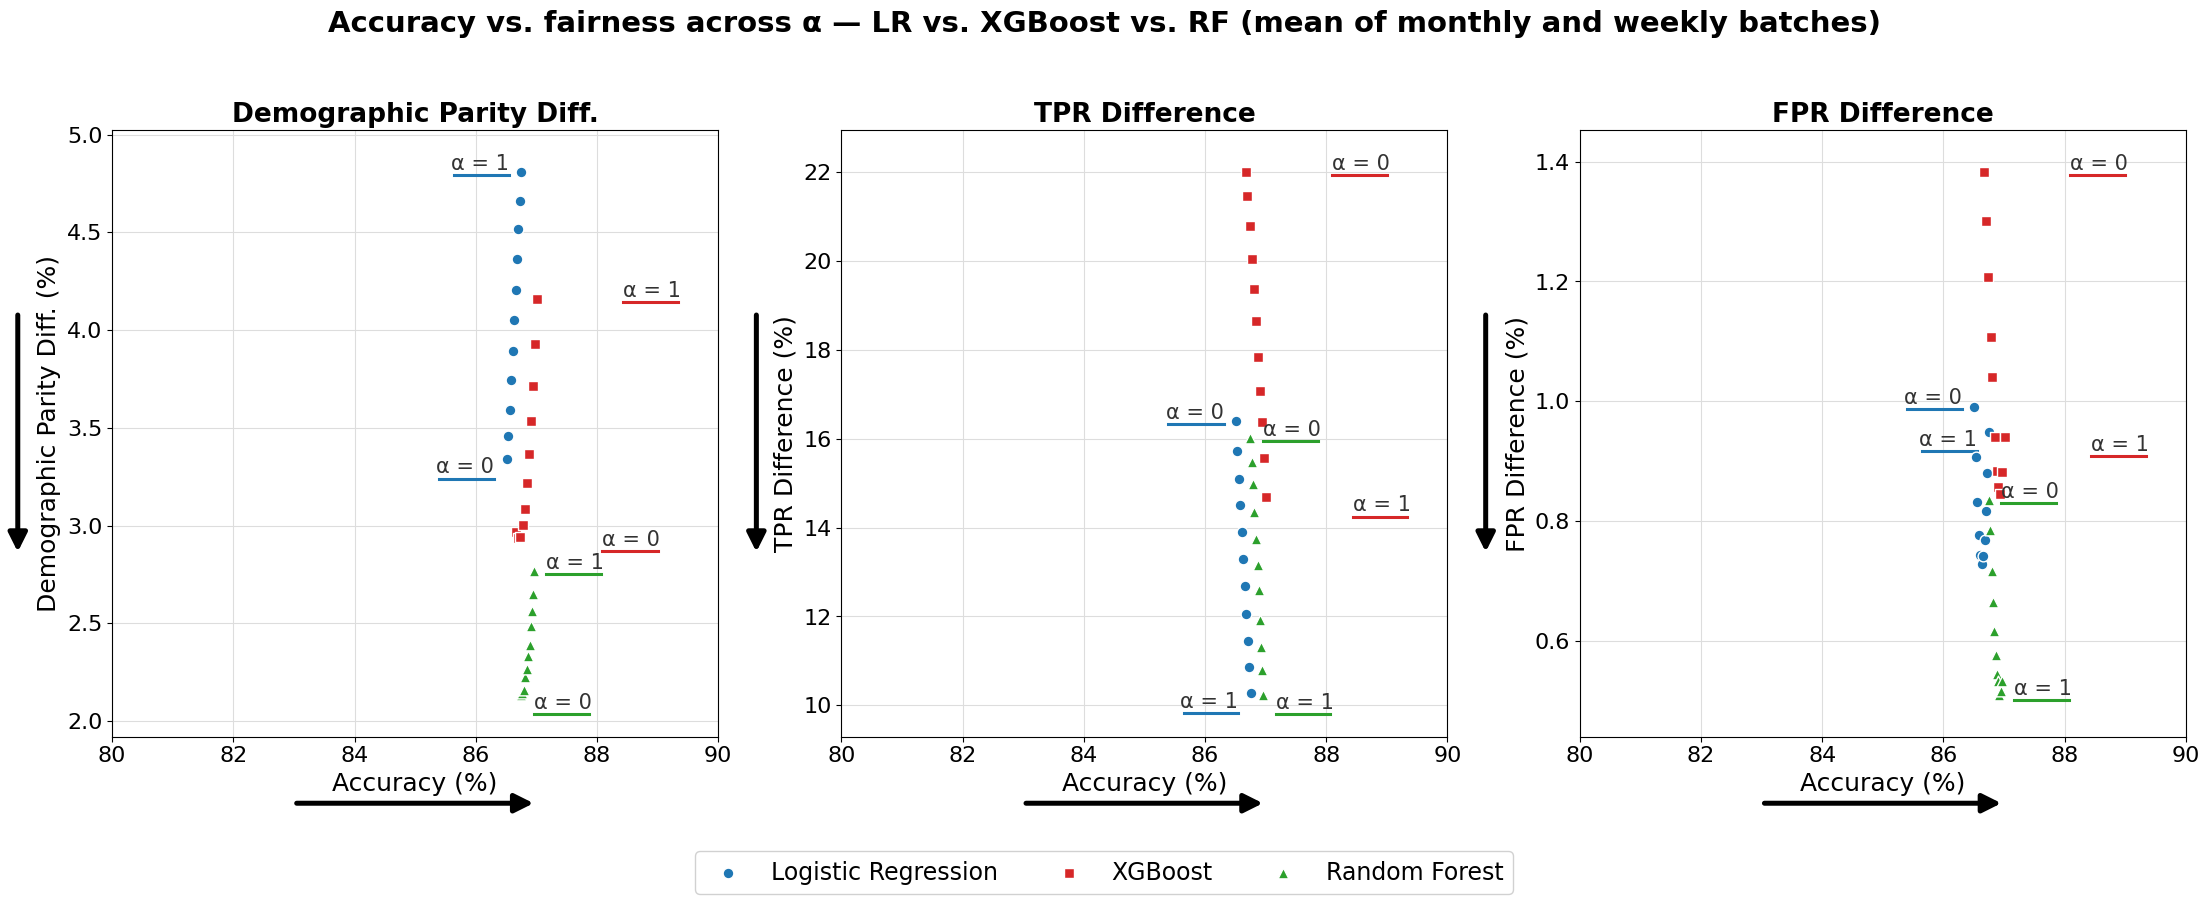

In [21]:
def plot_frontier_combined_trio(metrics=('dp', 'tpr_diff', 'fpr_diff'), fs=15):
    """Figs. 5b/6b/7b lado a lado (1×3), cada painel quadrado, com uma legenda única."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(22, 9), layout='constrained')
    for ax, metric in zip(axes, metrics):
        _draw_frontier(ax, 'combined', metric, points_fn=frontier_points_pooled, fs=fs)
        ax.set_box_aspect(1)
        ax.set_title(METRIC_LABELS[metric], fontsize=fs + 4, fontweight='bold')
        ax.get_legend().remove()
    handles, labels = axes[0].get_legend_handles_labels()
    # As setas 'better' ficam fora dos eixos e o layout as ignora: reserva uma faixa no rodapé
    # para a legenda, abaixo delas (no topo ela colide com o suptitle)
    fig.get_layout_engine().set(rect=(0, 0.09, 1, 0.91))
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0), ncol=len(handles), fontsize=fs + 2, framealpha=0.9)
    fig.suptitle('Accuracy vs. fairness across α — LR vs. XGBoost vs. RF (mean of monthly and weekly batches)',
                 fontsize=fs + 6, fontweight='bold')
    return fig


save_fig(plot_frontier_combined_trio(), 'fig05c_frontier_dp_tpr_fpr_combined.png')

## 4. Forecasting Techniques Analysis (seção 4.4)

In [24]:
# ── Carrega e concatena os forecast_quality.csv (só IDADE_BIN, atributo do artigo) ──
fq_root = ROOT / 'src' / 'results' / 'forecast_quality'
_folder_re = re.compile(
    r'(?P<batch_type>monthly|weekly)_forecast_window_(?P<forecast_window>\d+)_ema_alpha_(?P<ema_alpha>[\d.]+)'
)

frames = []
for csv_path in sorted((fq_root / 'IDADE_BIN').rglob('forecast_quality.csv')):
    m = _folder_re.match(csv_path.parent.name)
    # Figs. 8/9: EMA com alpha 0.3; as pastas com alpha 0.5 (mesmo EMA dos runs) são usadas só na 10c
    if m is None or float(m.group('ema_alpha')) != 0.3:
        continue
    d = pd.read_csv(csv_path)
    d['batch_type'] = m.group('batch_type')
    d['forecast_window'] = int(m.group('forecast_window'))
    d['ema_alpha'] = float(m.group('ema_alpha'))
    frames.append(d)
fq_df = pd.concat(frames, ignore_index=True)

# ── Período epidemiológico por linha ────────────────────────────────────────
_PERIOD_BINS = [
    pd.Timestamp('2000-01-01'),
    pd.Timestamp('2020-03-01'),   # pre-pandemic     < 2020-03
    pd.Timestamp('2022-01-01'),   # acute pandemic 1
    pd.Timestamp('2023-01-01'),   # acute pandemic 2
    pd.Timestamp('2024-01-01'),   # transition
    pd.Timestamp('2100-01-01'),   # endemic          >= 2024-01
]


def add_period_column(df):
    """batch -> data conforme batch_type (o rótulo é ambíguo entre mês e semana) -> período."""
    dt_map = {}
    for bt in df['batch_type'].unique():
        labels = df.loc[df['batch_type'] == bt, 'batch'].astype(str).unique().tolist()
        dt_map.update({(lab, bt): dt for lab, dt in zip(labels, _batch_to_datetime(labels, bt))})
    df['batch_dt'] = pd.to_datetime([dt_map[(str(b), bt)] for b, bt in zip(df['batch'], df['batch_type'])])
    df['period'] = pd.cut(df['batch_dt'], bins=_PERIOD_BINS, labels=PERIOD_ORDER_EN, right=False, ordered=True)
    return df


fq_df = add_period_column(fq_df)
print(f'{len(fq_df):,} linhas de {len(frames)} arquivos')
print('batch_type:', sorted(fq_df['batch_type'].unique()),
      '| forecast_window:', sorted(fq_df['forecast_window'].unique()))

10,872 linhas de 6 arquivos
batch_type: ['monthly', 'weekly'] | forecast_window: [np.int64(3), np.int64(5), np.int64(10)]


In [ ]:
_FORECASTER_ORDER = ['sma', 'ema']
_BT_ORDER = ['monthly', 'weekly']

mae_agg_bt = (
    fq_df.groupby(['batch_type', 'forecaster', 'period'], observed=True)['abs_error']
    .mean()
    .rename('mae_mean')
    .reset_index()
)

### Tabela 8 — MAE do forecast por período (SMA e EMA; monthly e weekly)

In [ ]:
# Tabela 8b: mesmos números da Fig. 8b (EMA alpha 0.3; janelas 3, 5 e 10 agrupadas), em formato tabular
_PERIOD_SHORT = {
    'pre-pandemic': 'Pre-pandemic',
    'acute pandemic 1': 'Acute 1',
    'acute pandemic 2': 'Acute 2',
    'transition': 'Transition',
    'endemic': 'Endemic',
}


def mae_by_period_table():
    """MAE do forecast (forecaster x batch type) por período e no total, no formato da Fig. 8b."""
    per = mae_agg_bt.pivot(index=['batch_type', 'forecaster'], columns='period', values='mae_mean')
    per = per.reindex(columns=PERIOD_ORDER_EN)
    per['overall'] = fq_df.groupby(['batch_type', 'forecaster'], observed=True)['abs_error'].mean()
    return per.reindex([(bt, fk) for bt in BT_ORDER for fk in _FORECASTER_ORDER])


def mae_by_period_latex(label='tab:forecast-mae-period'):
    tbl = mae_by_period_table()
    cols = PERIOD_ORDER_EN + ['overall']
    lines = [
        r'\begin{table}',
        r'  \small',
        r'  \caption{Forecast error (MAE $\downarrow$) of the SMA and EMA forecasters by epidemiological period. '
        r'MAE is the mean absolute error between the forecasted and the observed joint proportions '
        r'$p(S,Y)$, averaged over batches, over the four $(S,Y)$ cells and over forecast windows '
        r'$\{3,5,10\}$; EMA uses $\alpha=0.3$. Best forecaster per batch type in bold.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{ll' + 'r' * len(cols) + '}',
        r'    \toprule',
        '    Batch type & Forecaster & ' + ' & '.join(_PERIOD_SHORT.get(c, 'Overall') for c in cols) + r' \\',
    ]
    for bt in BT_ORDER:
        lines.append(r'    \midrule')
        best = {c: tbl.loc[bt][c].min() for c in cols}
        for i, fk in enumerate(_FORECASTER_ORDER):
            cells = [rf'\textbf{{{tbl.loc[(bt, fk), c]:.4f}}}' if tbl.loc[(bt, fk), c] == best[c]
                     else f'{tbl.loc[(bt, fk), c]:.4f}' for c in cols]
            lines.append(f"    {bt.capitalize() if i == 0 else ''} & {fk.upper()} & " + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, 'tab08b_mae_by_period.tex')


print(mae_by_period_latex())
mae_by_period_table().round(4)

### Fig. 6 — Forecast EMA × valor real (monthly e weekly no mesmo eixo)

In [ ]:
_PROPORTIONS = ['S0_Y0', 'S0_Y1', 'S1_Y0', 'S1_Y1']
_FORECASTER_STYLE = {'sma': '#1f77b4', 'ema': '#ff7f0e'}

# forecast: média sobre as janelas (mantém proporção/forecaster separados)
fc = fq_df.groupby(['batch_type', 'proportion', 'forecaster', 'batch'], as_index=False)['forecast_value'].mean()
# real: idêntico entre forecasters/janelas
rv = fq_df.groupby(['batch_type', 'proportion', 'batch'], as_index=False)['real_value'].mean()


Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig09b_forecast_vs_real_combined.png


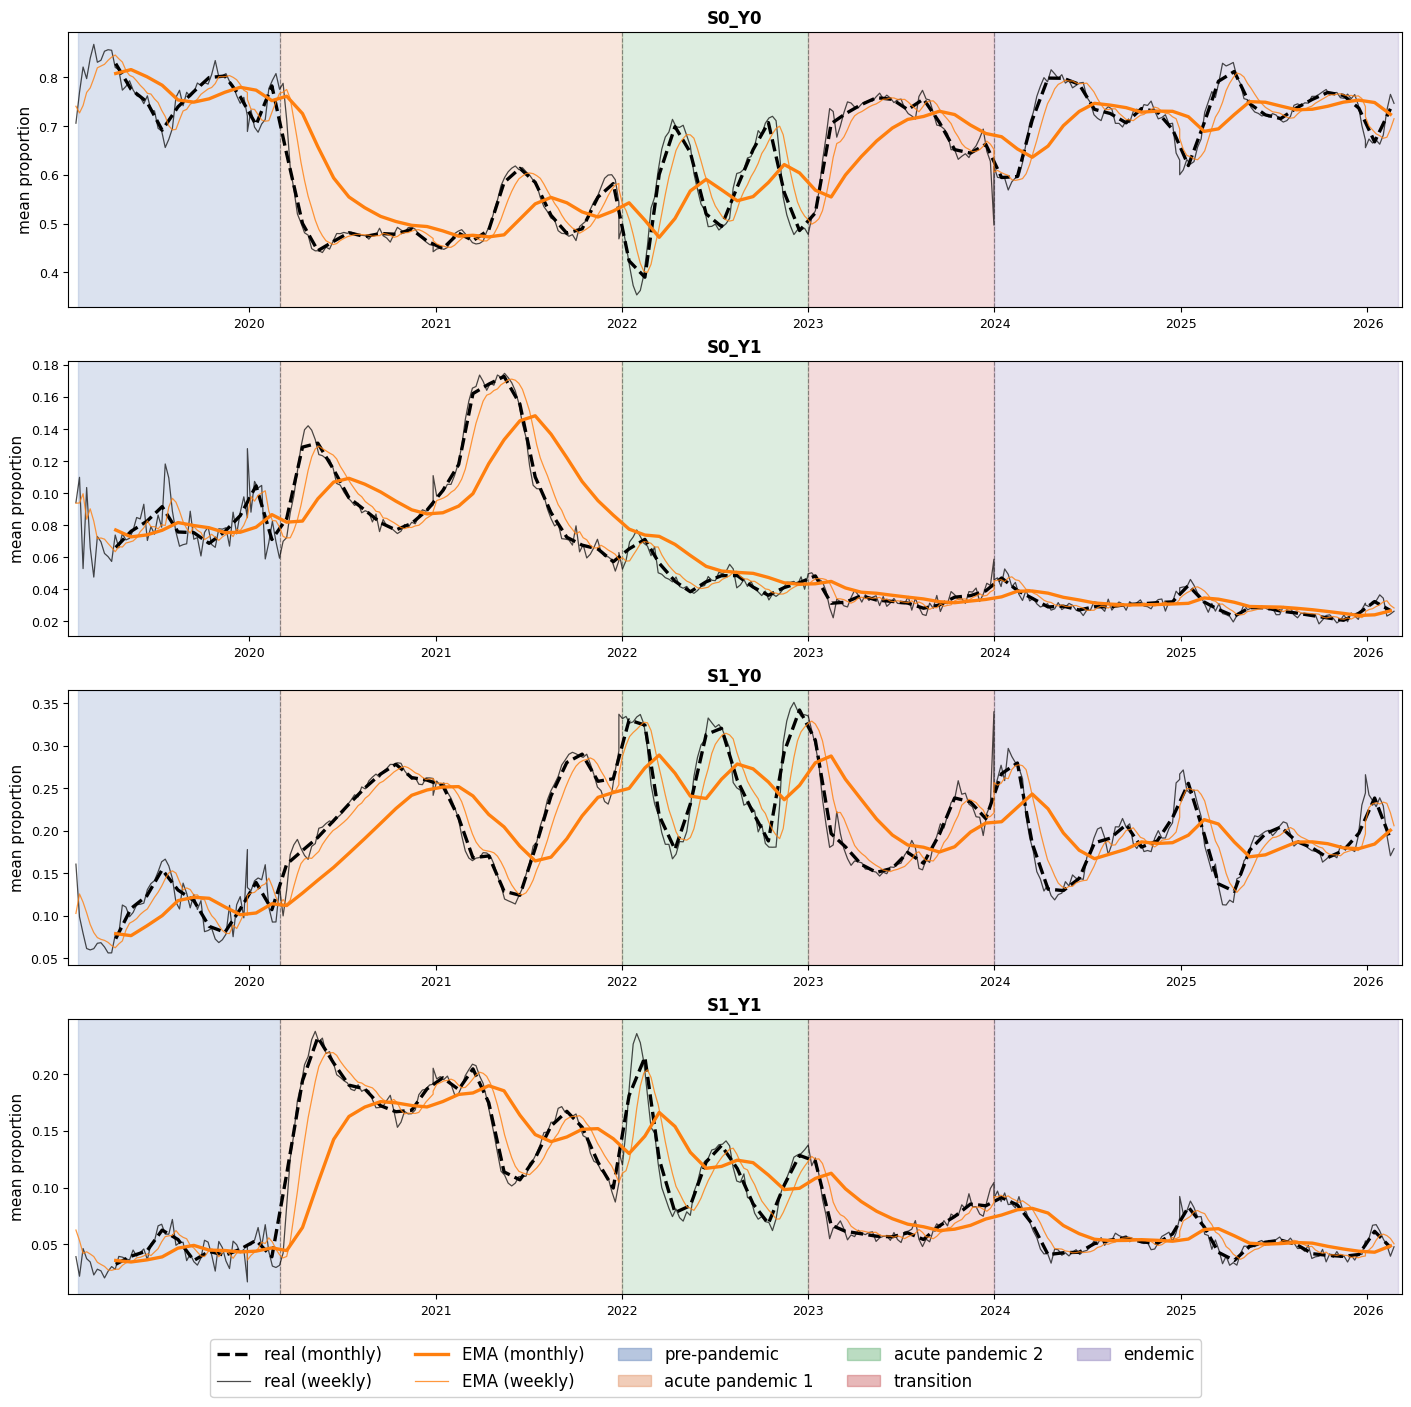

In [28]:
# Cor = série (real preto, EMA laranja); batch type = espessura: monthly grosso, weekly fino.
# SMA fica de fora (quase coincide com o EMA); monthly no meio do mês (ver batch_dates).
_SERIES_9B = [
    ('real', 'monthly', rv, 'real_value', dict(color='black', linewidth=2.4, linestyle='--')),
    ('real', 'weekly', rv, 'real_value', dict(color='black', linewidth=0.9, alpha=0.7)),
    ('EMA', 'monthly', fc[fc['forecaster'] == 'ema'], 'forecast_value', dict(color='#ff7f0e', linewidth=2.4)),
    ('EMA', 'weekly', fc[fc['forecaster'] == 'ema'], 'forecast_value', dict(color='#ff7f0e', linewidth=0.9, alpha=0.8)),
]

fig, axes = plt.subplots(len(_PROPORTIONS), 1, figsize=(14, 14), squeeze=False, layout='constrained')
all_dates = []
for r, prop in enumerate(_PROPORTIONS):
    ax = axes[r][0]
    period_handles = add_period_spans_dt(ax)
    series_handles = []
    for name, bt, src, col, style in _SERIES_9B:
        sub = src[(src['batch_type'] == bt) & (src['proportion'] == prop)].copy()
        sub['dt'] = batch_dates(sub['batch'], bt)
        sub = sub.sort_values('dt')
        all_dates.extend(sub['dt'])
        line, = ax.plot(sub['dt'], sub[col], label=f'{name} ({bt})', zorder=3, **style)
        series_handles.append(line)
    ax.set_title(prop, fontsize=12, fontweight='bold')
    ax.set_ylabel('mean proportion', fontsize=11)
    ax.tick_params(axis='both', labelsize=9)

for ax in fig.axes:
    fmt_date_axis(ax, all_dates)

# faixa reservada no rodapé: a legenda fica abaixo dos anos do eixo x, com folga
fig.get_layout_engine().set(rect=(0, 0.06, 1, 0.94))
leg = fig.legend(series_handles + period_handles, [h.get_label() for h in series_handles + period_handles],
                 loc='lower center', bbox_to_anchor=(0.5, 0), ncol=5, fontsize=12, framealpha=0.9)
for lp in leg.get_patches():
    lp.set_alpha(0.4)
save_fig(fig, 'fig09b_forecast_vs_real_combined.png', dpi=150)

### Tabela 9 — erro de previsão × fairness (LR e XGBoost, SMA / EMA / Oracle)

In [ ]:
# Mesma configuração dos runs de fairness: forecast window 5 e EMA com alpha_ema 0.5
# (a Fig. 8 usa o EMA com alpha 0.3). Oracle = previsão perfeita, MAE = 0 por definição.
MODELS_10C = ['logistic_regression', 'xgboost']
TECH_10C = ['sma', 'ema', 'oracle']
_TECH_LABEL3 = {'sma': 'SMA', 'ema': 'EMA', 'oracle': 'Oracle'}
FAIRNESS_10C = [m for m in ARTICLE_METRICS if m[0] in ('dp', 'tpr_diff', 'fpr_diff')]
fair_cols_10c = [c for c, _ in FAIRNESS_10C]


def pooled_mean(df, keys, cols):
    """Média por batch type e depois média entre os batch types (pesos iguais, como na Fig. 4c)."""
    per_bt = df.groupby(keys + ['batch_type'], observed=True)[cols].mean()
    return per_bt.groupby(level=keys, observed=True).mean()


# fairness do abcinml por batch (média sobre os 11 alphas)
fair_10c = load_filtered('assessment_all_baselines.csv', MODELS_10C, technique=TECH_10C)
fair_10c = fair_10c[(fair_10c['baseline'] == 'abcinml') & (fair_10c['forecast_window'] == 5)]
fair_batch_10c = add_period_column(
    fair_10c.groupby(['model_name', 'forecasting_technique', 'batch_type', 'batch'], as_index=False)[fair_cols_10c].mean()
)
fair_period_10c = pooled_mean(fair_batch_10c, ['model_name', 'forecasting_technique', 'period'], fair_cols_10c) * 100

# erro de previsão com a mesma configuração (fw 5, EMA alpha 0.5)
fq_10c = pd.concat([
    pd.read_csv(fq_root / 'IDADE_BIN' / f'{bt}_forecast_window_5_ema_alpha_0.5' / 'forecast_quality.csv').assign(batch_type=bt)
    for bt in BT_ORDER
], ignore_index=True)
mae_10c = pooled_mean(add_period_column(fq_10c), ['forecaster', 'period'], ['abs_error'])['abs_error'].to_dict()
mae_10c.update({('oracle', p): 0.0 for p in PERIOD_ORDER_EN})

pd.Series(mae_10c).unstack(0).reindex(index=PERIOD_ORDER_EN, columns=TECH_10C).round(4)

In [ ]:
def error_vs_fairness_table():
    """Fig. 10c em forma de tabela: MAE e fairness por modelo × técnica, na mesma agregação da figura
    (média simples dos 5 períodos; monthly e weekly com pesos iguais dentro de cada período)."""
    rows = []
    for model in MODELS_10C:
        for t in TECH_10C:
            row = {'model': model, 'tech': t, 'mae': np.mean([mae_10c[(t, p)] for p in PERIOD_ORDER_EN])}
            for col in fair_cols_10c:
                row[col] = np.mean([fair_period_10c.loc[(model, t, p), col] for p in PERIOD_ORDER_EN])
            rows.append(row)
    return pd.DataFrame(rows)


def error_vs_fairness_latex(label='tab:forecast-error-fairness'):
    tbl = error_vs_fairness_table()
    headers = {'dp': r'DP Diff. $\downarrow$', 'tpr_diff': r'TPR Diff. $\downarrow$', 'fpr_diff': r'FPR Diff. $\downarrow$'}
    lines = [
        r'\begin{table}',
        r'  \small',
        r'  \caption{Forecast error and ABCInML fairness by forecasting technique (forecast window = 5; EMA '
        r'$\alpha=0.5$; ABCInML = mean over $\alpha$). Forecast MAE is the mean absolute error of the forecasted '
        r'joint proportions $p(S,Y)$ (the Oracle is a perfect forecast, MAE $=0$). Fairness is the difference between '
        r'groups (\%), averaged over the five epidemiological periods and over monthly and weekly batches; '
        r'in parentheses, the change relative to SMA in percentage points. Best per model in bold.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{llrrrr}',
        r'    \toprule',
        r'    Model & Technique & Forecast MAE $\downarrow$ & ' + ' & '.join(headers[c] for c in fair_cols_10c) + r' \\',
    ]
    for model in MODELS_10C:
        lines.append(r'    \midrule')
        g = tbl[tbl['model'] == model].set_index('tech')
        best = {c: round(g[c].min(), 2) for c in fair_cols_10c}  # empates no valor exibido ficam todos em negrito
        for i, t in enumerate(TECH_10C):
            cells = [f"{g.loc[t, 'mae']:.4f}"]
            for c in fair_cols_10c:
                v = round(g.loc[t, c], 2)
                d = round(v - round(g.loc['sma', c], 2), 2)
                txt = rf'{v:.2f}\%' + ('' if t == 'sma' else (' (0.00)' if d == 0 else f' ({d:+.2f})'))
                cells.append(rf'\textbf{{{txt}}}' if v == best[c] else txt)
            lines.append(f"    {MODEL_LABELS[model] if i == 0 else ''} & {_TECH_LABEL3[t]} & " + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, 'tab10f_forecast_error_vs_fairness.tex')


print(error_vs_fairness_latex())
error_vs_fairness_table().round(4)

### Tabelas 6 e 7 — baselines por modelo e métricas temporais por modelo (seção 5.2)

`kamiran_rw`, `train_window = none`, `forecast_window = 5` (`FORECAST_WINDOW`), SMA; abcinml = média sobre os 11 alphas;
monthly e weekly com pesos iguais.

In [ ]:
FW_43 = FORECAST_WINDOW
MODELS_4C = ['logistic_regression', 'xgboost', 'random_forest']
cols_43 = ['acc', 'auc', 'dp', 'tpr_diff', 'fpr_diff']
FAIR_43 = ['dp', 'tpr_diff', 'fpr_diff']
BASE_43 = ['vanilla', 'static', 'dynamic', 'abcinml']
BASE_LABEL_43 = {'vanilla': 'Vanilla', 'static': 'Static', 'dynamic': 'Dynamic', 'abcinml': 'ABCInML'}

# abcinml = média sobre os alphas, por (modelo, baseline, batch type, batch)
lvl_43 = (
    assessment_df[(assessment_df['forecast_window'] == FW_43) & assessment_df['model_name'].isin(MODELS_4C)]
    .groupby(['model_name', 'baseline', 'batch_type', 'batch'], as_index=False)[cols_43].mean()
)
lvl_43['batch'] = lvl_43['batch'].astype(str)
means_43 = pooled_mean(lvl_43, ['model_name', 'baseline'], cols_43) * 100


means_43.round(2)

In [ ]:
def _fmt(v, best, suffix=r'\%'):
    return rf'\textbf{{{v:.2f}{suffix}}}' if v == best else f'{v:.2f}{suffix}'


def summary_models_latex(label='tab:baselines-models'):
    """Tab. 6c: 4 baselines × 3 modelos; DP/TPR/FPR/Acc/AUC, redução do DP vs. vanilla e ABCInML − Dynamic."""
    heads = [r'Accuracy $\uparrow$', r'AUC-ROC $\uparrow$', r'DP $\downarrow$', r'TPR $\downarrow$',
             r'FPR $\downarrow$', r'DP red. $\uparrow$']
    lines = [
        r'\begin{table}',
        r'  \small',
        r'  \caption{Baselines by model (forecast window = 5; mean of monthly and weekly batches; ABCInML = mean '
        r'over $\alpha$). TPR, FPR and DP are differences between groups. DP red.: reduction of DP relative to '
        r'Vanilla. Last row of each block: ABCInML $-$ Dynamic in percentage points. Best per model in bold.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{ll' + 'r' * len(heads) + '}',
        r'    \toprule',
        '    Model & Baseline & ' + ' & '.join(heads) + r' \\',
    ]
    for model in MODELS_4C:
        lines.append(r'    \midrule')
        m = means_43.loc[model]
        best = {c: (m.loc[BASE_43, c].max() if c in ('acc', 'auc') else m.loc[BASE_43, c].min()) for c in cols_43}
        for i, b in enumerate(BASE_43):
            cells = [_fmt(m.loc[b, c], best[c]) for c in cols_43]
            red = 100 * (1 - m.loc[b, 'dp'] / m.loc['vanilla', 'dp'])
            cells.append('--' if b == 'vanilla' else rf'{red:.1f}\%')
            lines.append(f"    {MODEL_LABELS[model] if i == 0 else ''} & {BASE_LABEL_43[b]} & " + ' & '.join(cells) + r' \\')
        diff = m.loc['abcinml'] - m.loc['dynamic']
        lines.append(r'     & ABCInML $-$ Dynamic & ' + ' & '.join(f'{diff[c]:+.2f}' for c in cols_43) + r' & \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, 'tab06c_baselines_models.tex')


def temporal_baselines_latex(label='tab:temporal-baselines-models'):
    """Tab. 5c: métricas temporais, 4 baselines × 3 modelos, monthly e weekly lado a lado."""
    tmp = (temporal_df[(temporal_df['forecast_window'] == FW_43) & temporal_df['model_name'].isin(MODELS_4C)]
           .groupby(['model_name', 'baseline', 'batch_type'])[TEMPORAL_METRICS].mean() * 100)
    heads = ['Max. Bias', 'Temporal Stability', 'Max. Bias Diff.']
    lines = [
        r'\begin{table}',
        r'  \small',
        r'  \caption{Temporal fairness metrics (DP) by baseline and model (forecast window = 5; ABCInML = mean '
        r'over $\alpha$). M = monthly, W = weekly. Best per model and column in bold.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{ll' + 'rr' * len(TEMPORAL_METRICS) + '}',
        r'    \toprule',
        '     & & ' + ' & '.join(rf'\multicolumn{{2}}{{c}}{{{h} $\downarrow$}}' for h in heads) + r' \\',
        '    ' + ' '.join(rf'\cmidrule(lr){{{3 + 2 * i}-{4 + 2 * i}}}' for i in range(len(TEMPORAL_METRICS))),
        '    Model & Baseline & ' + ' & '.join(['M & W'] * len(TEMPORAL_METRICS)) + r' \\',
    ]
    for model in MODELS_4C:
        lines.append(r'    \midrule')
        sub = tmp.loc[model]
        best = {(m, bt): sub.xs(bt, level='batch_type')[m].loc[BASE_43].min()
                for m in TEMPORAL_METRICS for bt in BT_ORDER}
        for i, b in enumerate(BASE_43):
            cells = [_fmt(sub.loc[(b, bt), m], best[(m, bt)]) for m in TEMPORAL_METRICS for bt in BT_ORDER]
            lines.append(f"    {MODEL_LABELS[model] if i == 0 else ''} & {BASE_LABEL_43[b]} & " + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, 'tab05c_temporal_baselines_models.tex')


print(summary_models_latex())
print(temporal_baselines_latex())

## 5. Dataset analytics (seção 4.1 — Dataset Review)

Estatísticas descritivas do SRAG: tamanho, tipos, funil do pré-processamento, taxas-base por período, ausências, shift nas variáveis, seleção e proxies. A parte bruta (8 parquets) roda só com `RUN_EDA = True`; o restante lê o cache do pré-processamento (`IDADE_BIN`). Opções e números de referência em `docs/dataset_analytics_opcoes.md`.

In [ ]:
import pyarrow.parquet as pq  # noqa: E402
import data_utils  # noqa: E402

RAW_DIR = ROOT / 'src' / 'data' / 'SRAG' / 'raw'
CACHE_DIR = ROOT / 'src' / 'data' / 'SRAG' / 'cache'
WINDOW_START, WINDOW_END = pd.Timestamp('2019-01-01'), pd.Timestamp('2026-03-01')  # [2019-01, 2026-02]
# colunas lidas por data_utils._import_data (42 das 194 do arquivo bruto)
DS_COLS = [
    'DT_NOTIFIC', 'EVOLUCAO', 'CS_RACA', 'NU_IDADE_N', 'CS_GESTANT', 'NOSOCOMIAL', 'AVE_SUINO', 'FEBRE', 'TOSSE',
    'GARGANTA', 'DISPNEIA', 'DESC_RESP', 'SATURACAO', 'DIARREIA', 'VOMITO', 'DOR_ABD', 'FADIGA', 'PERD_OLFT',
    'PERD_PALA', 'OUTRO_SIN', 'FATOR_RISC', 'PUERPERA', 'CARDIOPATI', 'HEMATOLOGI', 'SIND_DOWN', 'HEPATICA', 'ASMA',
    'DIABETES', 'NEUROLOGIC', 'PNEUMOPATI', 'IMUNODEPRE', 'RENAL', 'OBESIDADE', 'VACINA_COV', 'ANTIVIRAL', 'TP_ANTIVIR',
    'UTI', 'SUPORT_VEN', 'RAIOX_RES', 'TOMO_RES', 'CLASSI_FIN', 'SG_UF_NOT',
]


def load_raw_full():
    """Os 8 arquivos anuais com as colunas usadas; devolve também (linhas, colunas do arquivo) por arquivo."""
    parts, per_file = [], {}
    for f in sorted(RAW_DIR.glob('*.parquet')):
        d = pd.read_parquet(f, columns=DS_COLS)
        per_file[f.name] = (len(d), len(pq.read_schema(f).names))
        parts.append(d)
    return pd.concat(parts, ignore_index=True), per_file


def preprocessing_funnel(raw):
    """Registros que restam após cada regra, na ordem em que o código as aplica."""
    steps = [('Raw records (eight yearly files)', len(raw))]
    steps.append(('Outcome and race reported', len(raw.dropna(subset=['EVOLUCAO', 'CS_RACA']))))
    b = data_utils._fill_na(raw.copy())
    steps.append(('Race and pregnancy status not "unknown"', len(b)))
    c = b[pd.to_numeric(b['EVOLUCAO'], errors='coerce').isin([1, 2])]
    steps.append(('Outcome is recovery or death', len(c)))
    d = c[pd.to_numeric(c['NU_IDADE_N'], errors='coerce') < 120]
    steps.append(('Age below 120 years', len(d)))
    dt = pd.to_datetime(d['DT_NOTIFIC'], errors='coerce')
    steps.append(('Notified between 2019-01 and 2026-02', int(((dt >= WINDOW_START) & (dt < WINDOW_END)).sum())))
    return steps


def selection_by_year(raw):
    """Por ano de notificação: quanto falta de desfecho/raça e a letalidade de quem tem raça conhecida vs. ignorada."""
    r = pd.DataFrame({
        'dt': pd.to_datetime(raw['DT_NOTIFIC'], errors='coerce'),
        'ev': pd.to_numeric(raw['EVOLUCAO'], errors='coerce'),
        'race': pd.to_numeric(raw['CS_RACA'], errors='coerce'),
    })
    r = r[(r['dt'] >= WINDOW_START) & (r['dt'] < WINDOW_END)]
    r['year'] = r['dt'].dt.year
    r['race_unknown'] = r['race'].isna() | (r['race'] == 9)
    valid = r[r['ev'].isin([1, 2])]
    g = r.groupby('year')
    gv = valid.groupby(['year', 'race_unknown'])['ev'].apply(lambda s: (s == 2).mean() * 100).unstack()
    return pd.DataFrame({
        'n': g.size(),
        'outcome_missing': g['ev'].apply(lambda s: s.isna().mean() * 100),
        'outcome_other': g['ev'].apply(lambda s: s.isin([3, 9]).mean() * 100),
        'race_unknown': g['race_unknown'].mean() * 100,
        'death_race_known': gv[False],
        'death_race_unknown': gv[True],
    })


if RUN_EDA:
    raw_ds, per_file_ds = load_raw_full()
    funnel_ds = preprocessing_funnel(raw_ds)
    missing_ds = (raw_ds[DS_COLS].isna().mean() * 100).sort_values(ascending=False)
    n_raw_dtypes = raw_ds.dtypes.astype(str).value_counts().to_dict()
    selection_ds = selection_by_year(raw_ds)
    del raw_ds
    print(pd.DataFrame(funnel_ds, columns=['step', 'remaining']))
else:
    print('RUN_EDA = False — analytics do dataset (parte bruta) puladas')

In [ ]:
fp = data_utils._preprocessing_fingerprint()
_month_path, _week_path = (CACHE_DIR / f'IDADE_BIN_{w}_{fp}.parquet' for w in ('YEARMONTH', 'YEARWEEK'))
assert _month_path.exists() and _week_path.exists(), (
    f'cache do pré-processamento ausente ({fp}): rode o pipeline (data_utils.pre_process_df) para IDADE_BIN')
ds_month = pd.read_parquet(_month_path)
ds_week = pd.read_parquet(_week_path)
ds_month['period'] = pd.cut(ds_month['YEAR-MONTH'].dt.to_timestamp(), bins=_PERIOD_BINS, labels=PERIOD_ORDER_EN,
                            right=False, ordered=True)

_NON_FEATURES = ('EVOLUCAO', 'CS_RACA', 'YEAR-MONTH', 'IDADE_BIN', 'period')
_DUMMY_PREFIXES = ('AVE_SUINO_', 'CS_GESTANT_', 'TP_ANTIVIR_', 'SUPORT_VEN_', 'RAIOX_RES_', 'TOMO_RES_', 'CLASSI_FIN_')
ds_feats = [c for c in ds_month.columns if c not in _NON_FEATURES]
ds_dummies = [c for c in ds_feats if c.startswith(_DUMMY_PREFIXES)]
ds_binary = [c for c in ds_feats if c not in ds_dummies]

batches_month = ds_month.groupby('YEAR-MONTH').size()
batches_week = ds_week.groupby('YEAR-WEEK').size()

# perfil por período: tamanho, letalidade, grupo sensível e taxas-base P(Y | S)
_g = ds_month.groupby('period', observed=True)
profile_ds = pd.DataFrame({
    'n': _g.size(),
    'death': _g['EVOLUCAO'].mean() * 100,
    'old': _g['IDADE_BIN'].mean() * 100,
})
for s in (0, 1):
    sub = ds_month[ds_month['IDADE_BIN'] == s]
    profile_ds[f'p_y_s{s}'] = sub.groupby('period', observed=True)['EVOLUCAO'].mean() * 100
profile_ds.index = profile_ds.index.astype(str)
profile_ds.loc['Total'] = [
    len(ds_month), ds_month['EVOLUCAO'].mean() * 100, ds_month['IDADE_BIN'].mean() * 100,
    ds_month.loc[ds_month['IDADE_BIN'] == 0, 'EVOLUCAO'].mean() * 100,
    ds_month.loc[ds_month['IDADE_BIN'] == 1, 'EVOLUCAO'].mean() * 100,
]

# prevalência das variáveis binárias por período; as 8 com maior amplitude entre períodos
prevalence_ds = ds_month.groupby('period', observed=True)[ds_binary].mean() * 100
shift_top_ds = (prevalence_ds.max() - prevalence_ds.min()).nlargest(8).index.tolist()

# risco de proxies: correlação absoluta com o atributo sensível e com o alvo
corr_age_ds = ds_month[ds_feats].corrwith(ds_month['IDADE_BIN']).abs().nlargest(5)
corr_y_ds = ds_month[ds_feats].corrwith(ds_month['EVOLUCAO']).abs().nlargest(5)

print(f'{len(ds_month):,} registros mensais | {len(ds_week):,} semanais | {len(ds_feats)} features '
      f'({len(ds_binary)} binárias + {len(ds_dummies)} dummies)')
profile_ds.round(2)

In [ ]:
def _ds_table(caption, label, colspec, header, rows, filename, midrule_before=()):
    """Tabela booktabs simples; `rows` já vêm com as células separadas por ' & '."""
    lines = [r'\begin{table}', r'  \small', rf'  \caption{{{caption}}}', rf'  \label{{{label}}}',
             rf'  \begin{{tabular}}{{{colspec}}}', r'    \toprule', f'    {header} \\\\', r'    \midrule']
    for i, row in enumerate(rows):
        if i in midrule_before:
            lines.append(r'    \midrule')
        lines.append(f'    {row} \\\\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, filename)


def _tex(name):
    return name.replace('_', r'\_')


def _fmt_int(n):
    return f'{int(n):,}'


def ds_overview_latex():
    n_text = sum(v for k, v in n_raw_dtypes.items() if 'datetime' not in k)
    n_date = sum(v for k, v in n_raw_dtypes.items() if 'datetime' in k)
    cols_file = sorted({c for _, c in per_file_ds.values()})
    final_types = ds_month.drop(columns=['YEAR-MONTH', 'period']).dtypes.astype(str).value_counts()
    bm, bw = batches_month, batches_week
    rows = [
        rf'Source & SRAG, Brazilian Ministry of Health (SUS open data), {len(per_file_ds)} yearly files, 2019--2026',
        rf'Raw records & {_fmt_int(funnel_ds[0][1])}',
        rf'Columns per raw file / read & {cols_file[0]} / {len(DS_COLS)} ({n_text} text, {n_date} date)',
        rf'Records after preprocessing (monthly / weekly) & {_fmt_int(len(ds_month))} / {_fmt_int(len(ds_week))}',
        rf'Final columns & {ds_month.shape[1] - 1}: {len(ds_feats)} features ({len(ds_binary)} binary, {len(ds_dummies)} one-hot), '
        rf'target, race, sensitive attribute, window',
        rf'Final data types & {", ".join(f"{v} {k}" for k, v in final_types.items())} (window: monthly period)',
        rf'Time window & 2019-01 to 2026-02 ({len(bm)} monthly, {len(bw)} weekly batches)',
        rf'Monthly batch size (min / median / max) & {_fmt_int(bm.min())} / {_fmt_int(bm.median())} / {_fmt_int(bm.max())}',
        rf'Weekly batch size (min / median / max) & {_fmt_int(bw.min())} / {_fmt_int(bw.median())} / {_fmt_int(bw.max())}',
        rf'Target (positive class) & death, {profile_ds.loc["Total", "death"]:.2f}\% of records',
        rf'Sensitive attribute & age $\geq$ 65 years, {profile_ds.loc["Total", "old"]:.2f}\% of records',
    ]
    return _ds_table('Dataset overview (SRAG, 2019--2026): raw data and the dataset used in the experiments.',
                     'tab:dataset-overview', 'll', 'Item & Value', rows, 'tabds01_dataset_overview.tex')


def ds_funnel_latex():
    raw_n = funnel_ds[0][1]
    rows, prev = [], None
    for step, n in funnel_ds:
        removed = '--' if prev is None else _fmt_int(prev - n)
        rows.append(rf'{step} & {_fmt_int(n)} & {removed} & {n / raw_n * 100:.1f}\%')
        prev = n
    return _ds_table('Preprocessing funnel: records remaining after each rule (applied in this order).',
                     'tab:preprocessing-funnel', 'lrrr', r'Step & Remaining & Removed & \% of raw', rows,
                     'tabds02_preprocessing_funnel.tex')


def ds_profile_latex():
    rows = []
    for name, r in profile_ds.iterrows():
        rows.append(rf'{name} & {_fmt_int(r["n"])} & {r["death"]:.2f}\% & {r["old"]:.2f}\% & '
                    rf'{r["p_y_s0"]:.2f}\% & {r["p_y_s1"]:.2f}\%')
    return _ds_table(r'Profile by epidemiological period: size, death rate, share of the sensitive group (age $\geq$ 65) '
                     r'and base rates $P(Y=1\mid S)$ for the privileged ($S=0$) and sensitive ($S=1$) groups.',
                     'tab:period-profile', 'lrrrrr', r'Period & Records & Death & Age $\geq$ 65 & $P(Y\mid S=0)$ & $P(Y\mid S=1)$',
                     rows, 'tabds03_period_profile.tex', midrule_before=(len(profile_ds) - 1,))


def ds_missing_latex(top=12):
    rows = [rf'\texttt{{{_tex(c)}}} & {v:.1f}\%' for c, v in missing_ds.head(top).items()]
    return _ds_table(rf'Raw columns with the most missing values (top {top} of {len(DS_COLS)} read). Missing binary fields '
                     r'are treated as "condition did not occur".', 'tab:missing-raw', 'lr', r'Variable & Missing', rows,
                     'tabds04_missing_raw.tex')


def ds_shift_latex():
    rows = []
    for c in shift_top_ds:
        rows.append(rf'\texttt{{{_tex(c)}}} & ' + ' & '.join(f'{prevalence_ds.loc[p, c]:.1f}' for p in PERIOD_ORDER_EN))
    short = {'pre-pandemic': 'Pre-pand.', 'acute pandemic 1': 'Acute 1', 'acute pandemic 2': 'Acute 2',
             'transition': 'Transition', 'endemic': 'Endemic'}
    return _ds_table('Prevalence (\\%) of the binary variables with the largest change across periods.',
                     'tab:feature-shift', 'l' + 'r' * len(PERIOD_ORDER_EN),
                     'Variable & ' + ' & '.join(short[p] for p in PERIOD_ORDER_EN), rows, 'tabds05_feature_shift.tex')


def ds_selection_latex():
    rows = []
    for year, r in selection_ds.iterrows():
        rows.append(rf'{year} & {_fmt_int(r["n"])} & {r["outcome_missing"]:.1f}\% & {r["outcome_other"]:.1f}\% & '
                    rf'{r["race_unknown"]:.1f}\% & {r["death_race_known"]:.1f}\% & {r["death_race_unknown"]:.1f}\%')
    return _ds_table('Records affected by the cleaning rules, by notification year: missing outcome, outcome other than '
                     'recovery or death, unknown race, and death rate among records with a valid outcome and known or '
                     'unknown race.', 'tab:selection-by-year', 'lrrrrrr',
                     r'Year & Records & No outcome & Other outcome & Race unknown & Death (race known) & Death (race unknown)',
                     rows, 'tabds06_selection_by_year.tex')


def ds_proxy_latex():
    rows = []
    for (c1, v1), (c2, v2) in zip(corr_age_ds.items(), corr_y_ds.items()):
        rows.append(rf'\texttt{{{_tex(c1)}}} & {v1:.2f} & \texttt{{{_tex(c2)}}} & {v2:.2f}')
    return _ds_table(r'Features most correlated (absolute Pearson) with the sensitive attribute (age $\geq$ 65) and with the target.',
                     'tab:proxy-correlations', 'lrlr', r'Sensitive attribute & $|r|$ & Target (death) & $|r|$', rows,
                     'tabds07_proxy_correlations.tex')


def plot_records_per_batch(fs=12):
    fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, layout='constrained')
    all_dates, period_handles = [], []
    for ax, (bt, counts) in zip(axes, (('monthly', batches_month), ('weekly', batches_week))):
        ph = add_period_spans_dt(ax)
        period_handles = period_handles or ph
        dts = batch_dates(counts.index.astype(str), bt)
        all_dates.extend(dts)
        ax.plot(dts, counts.values, color='#333333', linewidth=1.8 if bt == 'monthly' else 1.1, zorder=3)
        ax.set_yscale('log')
        ax.set_ylabel(f'Records per {bt[:-2]}', fontsize=fs + 2)
        ax.tick_params(axis='both', labelsize=fs)
        ax.grid(axis='y', color='#dddddd', linewidth=0.7)
    for ax in axes:
        fmt_date_axis(ax, all_dates)
    leg = fig.legend(period_handles, [h.get_label() for h in period_handles], loc='outside lower center', ncol=5,
                     fontsize=fs - 1, framealpha=0.9)
    for lp in leg.get_patches():
        lp.set_alpha(0.4)
    return fig


if RUN_EDA:
    print(ds_overview_latex())
    print(ds_funnel_latex())
    print(ds_profile_latex())
    print(ds_missing_latex())
    print(ds_shift_latex())
    print(ds_selection_latex())
    print(ds_proxy_latex())
    save_fig(plot_records_per_batch(), 'figds01_records_per_batch.png', dpi=150)
else:
    print('RUN_EDA = False — tabelas/figura de analytics do dataset puladas')